# 09 · Ablation Studies and Calibration
**Owner:** Nakkina Lakshmi Praneeth (2401010288) · Phase 2 rubric: **ablation studies**, **DL regularisation**, **technical validation** (calibration)

**Builds on:** 06–08. **Writes:** `src/fdp/calibration.py`, `reports/09_ablation_calibration.json`, `reports/figures/09_*.png`.

**How it runs:** open it in Google Colab and choose *Runtime → Run all*. The ⚙️ Setup cell clones this repository and installs `requirements.txt`; each `%%writefile` cell generates the `.py` file named on its first line; the 📦 Export cell at the end packs the generated files and results into a zip, which is added to the repository together with the executed notebook.

| Section | What it answers |
|---|---|
| A · Ablation: what each part of the temporal model is worth | remove one part at a time, same honest protocol |
| B · Calibration: can a planner trust the probabilities? | temperature vs Platt scaling, chosen before the test months |

All of it uses **July–October only**. The test months stay closed until notebook 10.
⏱️ About 30–40 minutes on a Colab CPU, ~10 on a GPU. `QUICK_RUN` ≈ 8 minutes.

In [1]:
#@title ⚙️ 0 · Setup — run this cell first { display-mode: "form" }
#@markdown In **Colab** this clones the team repo and installs the requirements.
#@markdown Locally (Jupyter / VS Code) it just moves to the repo root.
REPO_URL = "https://github.com/mrstrange1708/T107_Flight_Delay_Prediction.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
QUICK_RUN = False  #@param {type:"boolean"}
#@markdown `QUICK_RUN` = smaller searches/samples so the notebook finishes in a few minutes (use it to check the code runs; keep it off for the final results).

import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("/content/aml-project/.git"):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, "/content/aml-project"], check=True)
    os.chdir("/content/aml-project")
    if os.path.exists("requirements.txt"):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
for d in ["src/fdp", "tests", "data/raw", "data/processed", "reports/figures"]:
    os.makedirs(d, exist_ok=True)
open("src/fdp/__init__.py", "a").close()
sys.path.insert(0, os.path.abspath("src"))

import warnings; warnings.filterwarnings("ignore")
import torch; torch.set_num_threads(max(1, os.cpu_count() or 1))
import json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Working directory:", os.getcwd(), "| Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

Working directory: /tmp/fdp | Colab: False | QUICK_RUN: False


In [2]:
import fdp.config as config, fdp.data as data, fdp.features as features, fdp.dl_inputs as dl, fdp.deep as deep
df = data.build_dataset(*data.load_raw())
X, groups = features.build_features(df)
NUM, CAT = features.numeric_columns(groups), config.CATEGORICAL
NO_HIST = [c for c in NUM if c not in groups["history"]]
S = data.split(X)
y = {k: v["delayed"].astype(int).to_numpy() for k, v in S.items()}
lab = pd.concat([S["train"], S["valid"]])
month = lab["date"].dt.month.to_numpy()
ylab = lab["delayed"].astype(int).to_numpy()
r08 = json.load(open("reports/08_temporal_hybrid.json"))
BODY = {k: (tuple(v) if k == "hidden" else v) for k, v in r08["body"].items()}
MONTHS = r08["months"]
roll08 = {r["model"]: r for r in r08["rolling"]}
seq = dl.build_sequences(df, lab)
print("body:", BODY, "| months:", MONTHS)

body: {'hidden': (256, 128), 'dropout': 0.5, 'lr': 0.0003, 'weight_decay': 0.01} | months: [7, 8, 9]


---
## A · Ablation: what each part of the temporal model is worth
**The full model** is notebook 08's *"Temporal: GRU replaces hand history"*: 19 numeric features without hand-made history, embeddings for carrier/origin/destination, a GRU over 14 days of **relative** rates, dropout + weight decay, early stopping. Each row changes **one** thing and is scored with the same honest rolling protocol and the same seed.

| Ablation | Question it answers |
|---|---|
| − GRU branch | how much do the ordered days add, once hand history is gone? |
| + hand-made history | do the 22 Phase 1 history features still add anything next to the GRU? |
| absolute rates in the sequence | does the "relative to the overall rate" choice (notebook 06) matter? |
| one-hot instead of embeddings | do learned embeddings beat one column per category? |
| 7-day sequence | is two weeks better than one? |
| no dropout, no weight decay | how much does regularisation matter? |
| no early stopping (fixed 15 epochs) | what happens if training just runs on? |

In [3]:
#@title 🎛️ Run the ablations { display-mode: "form" }
FIXED_EPOCHS = 15  #@param {type:"slider", min:5, max:30, step:1}
import time
full = dict(BODY, use_seq=True)
def run(name, cfg, cols, seq_arr):
    t = time.time()
    s, e = deep.rolling_eval_nn(lab, seq_arr, month, cfg, cols, CAT, months=MONTHS, seed=config.SEED)
    print(f"{name:40s} {np.round(s, 4)} mean {np.mean(s):.4f} epochs {e} ({time.time() - t:.0f} s)", flush=True)
    return {"ablation": name, "folds": s, "mean": float(np.mean(s)), "epochs": e}

rows = []
for name in ["Temporal: GRU replaces hand history", "Temporal: GRU + all features"]:
    r = roll08[name]
    s = [r[c] for c in ["Jul", "Aug", "Sep"] if c in r]
    rows.append({"ablation": {"Temporal: GRU replaces hand history": "full model",
                              "Temporal: GRU + all features": "+ hand-made history (22 features)"}[name],
                 "folds": s, "mean": float(np.mean(s)), "epochs": r08["epochs_per_fold"][name]})
rows.append(run("− GRU branch (MLP, no history)", BODY, NO_HIST, None))
seq_abs = dl.build_sequences(df, lab, relative=False)
rows.append(run("absolute rates in the sequence", full, NO_HIST, seq_abs)); del seq_abs
rows.append(run("one-hot instead of embeddings", dict(full, use_emb=False), NO_HIST, seq))
rows.append(run("7-day sequence", full, NO_HIST, np.ascontiguousarray(seq[:, -7:, :])))
rows.append(run("no dropout, no weight decay", dict(full, dropout=0.0, weight_decay=0.0), NO_HIST, seq))

# no early stopping: train FIXED_EPOCHS on all months before m, score m
s = []
for m in MONTHS:
    full_i, test_i = np.where(month < m)[0], np.where(month == m)[0]
    (dtr, dte), n_num, cards = deep.prepare(lab, seq, NO_HIST, CAT, full_i, [full_i, test_i], use_seq=True)
    net = deep.build_net(full, n_num, cards, seq.shape[2])
    net, _, _ = deep.train(net, dtr, ylab[full_i], epochs=FIXED_EPOCHS, seed=config.SEED, lr=BODY["lr"], weight_decay=BODY["weight_decay"])
    from sklearn.metrics import average_precision_score as ap
    s.append(float(ap(ylab[test_i], deep.predict_logits(net, dte))))
rows.append({"ablation": f"no early stopping ({FIXED_EPOCHS} epochs)", "folds": s, "mean": float(np.mean(s)), "epochs": [FIXED_EPOCHS] * len(MONTHS)})

ablation = pd.DataFrame(rows).set_index("ablation")
ablation["change vs full"] = ablation["mean"] - ablation.loc["full model", "mean"]
seed_range = {r["model"]: r["range"] for r in r08["seed_spread"]}.get("Temporal: GRU replaces hand history", float("nan"))
print(f"seed-to-seed range of the full model (notebook 08): {seed_range:.4f}")
ablation[["mean", "change vs full", "epochs"]].round(4)

− GRU branch (MLP, no history)           [0.5302 0.3651 0.2178] mean 0.3710 epochs [19, 15, 2] (119 s)


absolute rates in the sequence           [0.5578 0.3934 0.2839] mean 0.4117 epochs [11, 5, 11] (261 s)


one-hot instead of embeddings            [0.5626 0.4017 0.2592] mean 0.4079 epochs [13, 14, 6] (299 s)


7-day sequence                           [0.5611 0.4035 0.2625] mean 0.4090 epochs [16, 19, 9] (263 s)


no dropout, no weight decay              [0.5703 0.4024 0.2554] mean 0.4094 epochs [8, 8, 6] (157 s)


seed-to-seed range of the full model (notebook 08): 0.0030


,mean,change vs full,epochs
ablation,,,
full model,0.4111,0.0000,"[16, 19, 11]"
+ hand-made history (22 features),0.4086,-0.0025,"[8, 7, 2]"
"− GRU branch (MLP, no history)",0.3710,-0.0400,"[19, 15, 2]"
absolute rates in the sequence,0.4117,0.0007,"[11, 5, 11]"
one-hot instead of embeddings,0.4079,-0.0032,"[13, 14, 6]"
7-day sequence,0.4090,-0.0020,"[16, 19, 9]"
"no dropout, no weight decay",0.4094,-0.0017,"[8, 8, 6]"
no early stopping (15 epochs),0.4107,-0.0004,"[15, 15, 15]"


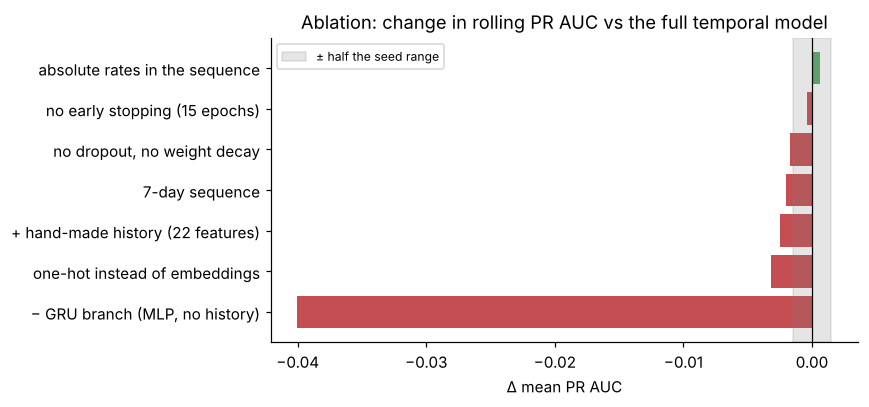

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
a = ablation["change vs full"].drop("full model").sort_values()
ax.barh(a.index, a.values, color=["#C44E52" if v < 0 else "#55A868" for v in a.values])
ax.axvline(0, color="black", lw=.8)
if seed_range == seed_range:
    ax.axvspan(-seed_range / 2, seed_range / 2, color="grey", alpha=.2, label="± half the seed range")
    ax.legend(fontsize=8)
ax.set(title="Ablation: change in rolling PR AUC vs the full temporal model", xlabel="Δ mean PR AUC")
fig.tight_layout(); fig.savefig("reports/figures/09_ablation.png"); plt.show()

**How to read it:** a bar inside the grey band is within seed noise: that part neither helps nor hurts measurably. A bar clearly to the left means removing that part **costs** accuracy, so it earns its place. Read the epochs column too: a part that makes the best epoch count jump around is making the model less stable even when the mean barely moves.

---
## B · Calibration: can a planner trust the probabilities?
Guo et al. (2017) showed modern networks are often **over-confident**. The deliverable asks for **calibrated probabilities**, and Phase 1's flag rule (calibrated p ≥ 0.5) depends on them.

**Set-up, test months untouched:** fit each model on Jan 15 – Aug for the epoch count chosen in notebook 08 (median over folds), fit the calibrators on **September**, and judge them on **October**, a month neither the model nor the calibrator has seen. September (13.7% late) and October (17.6%) have different base rates, the same kind of shift the test months bring (25.8%).

In [5]:
%%writefile src/fdp/calibration.py
"""Phase 2 · calibration: turning scores into probabilities a planner can trust.
Owner: Nakkina Lakshmi Praneeth (Praneeth).

Guo et al. (2017) showed that modern neural networks are often OVER-confident: their probabilities
are more extreme than the observed frequencies. Two fixes, both fitted on October (a month no model
is trained on) and both leave the ranking - and so PR AUC and ROC AUC - unchanged:
  temperature scaling  p = sigmoid(logit / T)           one number
  Platt scaling        p = sigmoid(a * logit + b)       two numbers (Phase 1 used this)
Platt's extra intercept b also shifts the overall level, which helps when the model is biased,
but it also copies October's base rate into the probabilities.
"""
import numpy as np
from scipy.optimize import minimize_scalar
from sklearn.linear_model import LogisticRegression


class TemperatureScaler:
    """Guo et al. (2017): divide the logit by one number T, fitted on a held-out month by
    minimising log loss. T > 1 softens over-confident probabilities; ranking (PR AUC) is unchanged."""

    def fit(self, logits, y):
        logits, y = np.asarray(logits, float), np.asarray(y, float)

        def nll(t):
            p = np.clip(1 / (1 + np.exp(-logits / t)), 1e-7, 1 - 1e-7)
            return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
        self.T = float(minimize_scalar(nll, bounds=(0.05, 20), method="bounded").x)
        return self

    def transform(self, logits):
        return 1 / (1 + np.exp(-np.asarray(logits, float) / self.T))


def sigmoid(z):
    return 1 / (1 + np.exp(-np.asarray(z, float)))




class PlattScaler:
    def fit(self, logits, y):
        self.m = LogisticRegression(C=1e6).fit(np.asarray(logits, float)[:, None], y)
        return self

    def transform(self, logits):
        return self.m.predict_proba(np.asarray(logits, float)[:, None])[:, 1]


def reliability(y, p, n_bins=10, min_count=100):
    """Points for a reliability diagram: mean predicted vs observed rate per probability bin."""
    y, p = np.asarray(y), np.asarray(p)
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    keep = [i for i in range(n_bins) if (b == i).sum() >= min_count]
    return [float(p[b == i].mean()) for i in keep], [float(y[b == i].mean()) for i in keep]

Overwriting src/fdp/calibration.py


In [6]:
import fdp.calibration as cal; importlib.reload(cal)
import fdp.metrics as metrics
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
import fdp.preprocess as prep
tr = np.where(month <= 8)[0]
models = {"MLP + embeddings": (dict(BODY), NUM, None),
          "Temporal: GRU replaces hand history": (dict(BODY, use_seq=True), NO_HIST, None),
          "Hybrid: LR + temporal correction": (dict(BODY, use_seq=True, use_offset=True), NO_HIST, NUM)}
seq_part = {"valid": dl.build_sequences(df, S["valid"]), "calib": dl.build_sequences(df, S["calib"])}
logit = {"valid": {}, "calib": {}}
lr = make_pipeline(prep.linear_preprocessor(NUM, CAT), LogisticRegression(C=config.PHASE1_LR_C, max_iter=3000)).fit(lab.iloc[tr], ylab[tr])
for part in logit:
    logit[part]["Logistic regression"] = lr.decision_function(S[part])
both = pd.concat([lab.iloc[tr], S["valid"], S["calib"]])
seq_both = np.concatenate([seq[tr], seq_part["valid"], seq_part["calib"]])
n_tr, n_va = len(tr), len(S["valid"])
parts = {"valid": np.arange(n_tr, n_tr + n_va), "calib": np.arange(n_tr + n_va, len(both))}
for name, (cfg, cols, off) in models.items():
    ep = int(np.median(r08["epochs_per_fold"][name]))
    (dtr, dva, dca), n_num, cards = deep.prepare(both, seq_both, cols, CAT, np.arange(n_tr), [np.arange(n_tr), parts["valid"], parts["calib"]],
                                                 cfg.get("use_seq", False), cfg.get("use_offset", False), offset_numeric=off)
    net = deep.build_net(cfg, n_num, cards, seq.shape[2])
    net, _, _ = deep.train(net, dtr, ylab[tr], epochs=ep, seed=config.SEED, lr=BODY["lr"], weight_decay=BODY["weight_decay"])
    logit["valid"][name], logit["calib"][name] = deep.predict_logits(net, dva), deep.predict_logits(net, dca)
    print(name, "epochs:", ep, flush=True)

rows, curves = [], {}
for name in logit["valid"]:
    T = cal.TemperatureScaler().fit(logit["valid"][name], y["valid"])
    P = cal.PlattScaler().fit(logit["valid"][name], y["valid"])
    raw, pt, pp = cal.sigmoid(logit["calib"][name]), T.transform(logit["calib"][name]), P.transform(logit["calib"][name])
    rows.append({"model": name, "T": T.T, "October ECE raw": metrics.ece(y["calib"], raw), "after temperature": metrics.ece(y["calib"], pt),
                 "after Platt": metrics.ece(y["calib"], pp), "mean p raw": raw.mean(), "mean p temperature": pt.mean(), "mean p Platt": pp.mean(),
                 "October PR AUC": metrics.evaluate(y["calib"], raw)["pr_auc"]})
    curves[name] = {"raw": cal.reliability(y["calib"], raw), "temperature": cal.reliability(y["calib"], pt), "Platt": cal.reliability(y["calib"], pp)}
calib = pd.DataFrame(rows).set_index("model")
print("October observed late rate:", round(y["calib"].mean(), 4), "| September:", round(y["valid"].mean(), 4))
calib.round(4)

MLP + embeddings epochs: 6


Temporal: GRU replaces hand history epochs: 16


Hybrid: LR + temporal correction epochs: 11


October observed late rate: 0.1756 | September: 0.1372


,T,October ECE raw,after temperature,after Platt,mean p raw,mean p temperature,mean p Platt,October PR AUC
model,,,,,,,,
Logistic regression,0.7155,0.0408,0.0262,0.0372,0.2144,0.1532,0.1390,0.3079
MLP + embeddings,0.7342,0.0363,0.0291,0.0354,0.2091,0.1542,0.1403,0.3133
Temporal: GRU replaces hand history,0.7864,0.0460,0.0358,0.0290,0.2196,0.1803,0.1515,0.3068
Hybrid: LR + temporal correction,0.7386,0.0407,0.0303,0.0356,0.2148,0.1626,0.1419,0.3090


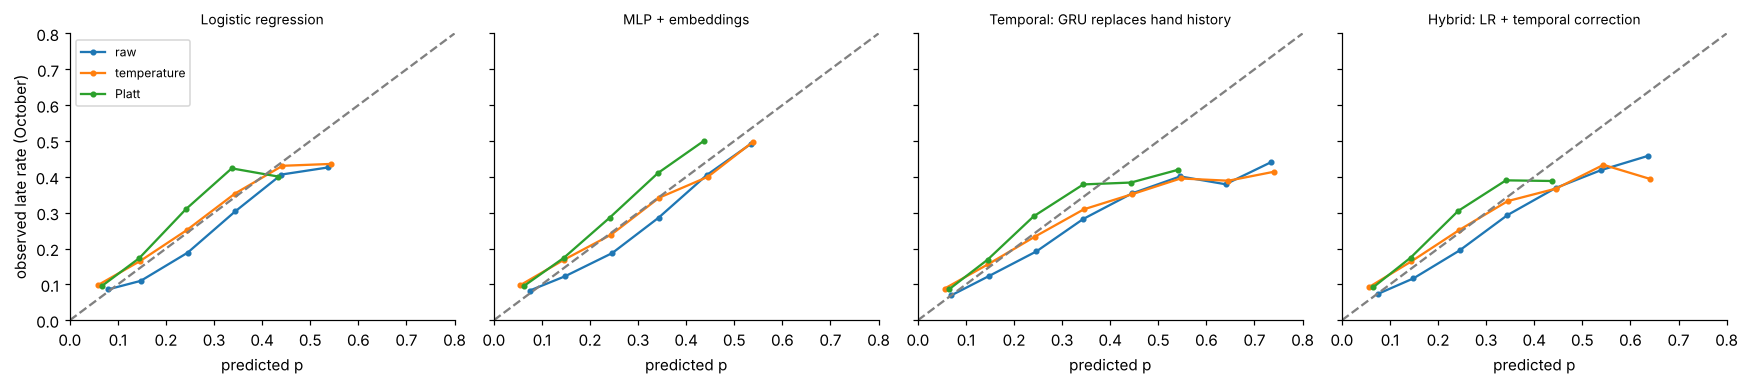

In [7]:
fig, ax = plt.subplots(1, len(curves), figsize=(4 * len(curves), 3.6), sharey=True)
for a, (name, c) in zip(ax, curves.items()):
    for k, (px, py) in c.items():
        a.plot(px, py, "o-", ms=3, label=k)
    a.plot([0, .8], [0, .8], "--", color="grey"); a.set(title=name, xlabel="predicted p", xlim=(0, .8), ylim=(0, .8))
    a.title.set_fontsize(9)
ax[0].set_ylabel("observed late rate (October)"); ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig("reports/figures/09_reliability_october.png"); plt.show()

In [8]:
CHOICE = "temperature" if calib["after temperature"].mean() <= calib["after Platt"].mean() else "Platt"
print("mean October ECE, temperature:", round(calib["after temperature"].mean(), 4), "| Platt:", round(calib["after Platt"].mean(), 4))
print("method used for every model in notebook 10:", CHOICE)

mean October ECE, temperature: 0.0303 | Platt: 0.0343
method used for every model in notebook 10: temperature


**How to read it:**
* **T > 1** means the raw network was over-confident (its logits are shrunk); T < 1 means under-confident. Guo et al. found T > 1 for deep image networks; a small, regularised, early-stopped tabular network need not be over-confident, so we **measure** rather than assume.
* **Temperature** has one parameter and keeps the model's own overall level; **Platt** has an intercept that copies the calibration month's base rate. When the base rate moves between months (13.7% → 17.6% → 25.8%), that intercept can hurt, which is what we saw for logistic regression in Phase 1.
* The method with the lower mean October ECE is used for **every** model in notebook 10, fitted on October; this choice is made here, before the test months.

In [9]:
out = {"ablation": ablation.reset_index().to_dict(orient="records"), "seed_range_full": seed_range, "fixed_epochs": FIXED_EPOCHS,
       "calibration": calib.reset_index().to_dict(orient="records"), "calibration_choice": CHOICE,
       "base_rates": {"September": float(y["valid"].mean()), "October": float(y["calib"].mean())}, "quick_run": QUICK_RUN}
with open("reports/09_ablation_calibration.json", "w") as f:
    json.dump(out, f, indent=2, default=float)
print("saved reports/09_ablation_calibration.json")

saved reports/09_ablation_calibration.json


---
## Summary
* **Ablation:** removing the GRU branch costs **−0.0400** in rolling PR AUC, the only change clearly outside the full model's seed range (0.0030). Adding back hand-made history (−0.0025), one-hot instead of embeddings (−0.0032), a 7-day sequence (−0.0020), no dropout or weight decay (−0.0017) and no early stopping (−0.0004) are all within about one seed range.
* **Relative rates** made no measurable difference (+0.0007 with absolute rates): the GRU also sees the overall rate as its own channel. The idea from notebook 06 did not pay off here.
* **Calibration:** every fitted temperature is below 1 (0.72–0.79), so these networks were under-confident, the opposite of Guo et al.'s image networks. Temperature scaling had the lower mean October ECE (0.030 vs 0.034 for Platt) and is used for every model in notebook 10.

**Next:** notebook 10 refits everything, scores the test months once and runs the what-if analysis.

In [10]:
#@title 📦 Export · pack the generated modules and results { display-mode: "form" }
#@markdown Zips the `.py` files this notebook generated with `%%writefile` and its results in `reports/`; in Colab the zip downloads automatically.
#@markdown The zip and the executed notebook (File → Download → Download .ipynb) are what gets added to the repository.
import glob, zipfile
FILES = [
    'src/fdp/calibration.py',
    'reports/09_ablation_calibration.json',
    'reports/figures/09_*.png',
]
paths = sorted({p for pattern in FILES for p in glob.glob(pattern)})
zip_name = "09_outputs.zip"
with zipfile.ZipFile(zip_name, "w") as z:
    for p in paths:
        z.write(p)
print("Packed", len(paths), "files into", zip_name)
for p in paths:
    print("  ", p)
if IN_COLAB:
    from google.colab import files
    files.download(zip_name)

Packed 4 files into 09_outputs.zip
   reports/09_ablation_calibration.json
   reports/figures/09_ablation.png
   reports/figures/09_reliability_october.png
   src/fdp/calibration.py
